<a href="https://colab.research.google.com/github/nurinnuhaa4/20262R0136DATA30200/blob/main/notebooks/01_dataset_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content

!git clone https://github.com/sihyeok000/DATA302_Final_Project.git

/content
Cloning into 'DATA302_Final_Project'...
remote: Enumerating objects: 303, done.
remote: Counting objects: 100% (303/303), done.
remote: Compressing objects: 100% (232/232), done.
remote: Total 303 (delta 60), reused 290 (delta 49), pack-reused 0 (from 0)
Receiving objects: 100% (303/303), 23.47 MiB | 19.09 MiB/s, done.
Resolving deltas: 100% (60/60), done.


In [2]:
%cd /content/DATA302_Final_Project

!ls

/content/DATA302_Final_Project
data  examples	main  mano_models  README.md  results  submodules  tools


In [3]:
!find data -maxdepth 3 -type f | head -30

data/README.md


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks']


In [6]:
from pathlib import Path

VIDEO_DIR = Path(
    "/content/drive/MyDrive/HOI_Project/original_videos"
)

video_files = sorted([
    p for p in VIDEO_DIR.iterdir()
    if p.suffix.lower() in [".mp4", ".mov", ".avi"]
])

print("Total videos found:", len(video_files))

for video in video_files:
    size_mb = video.stat().st_size / (1024 ** 2)
    print(f"{video.name} — {size_mb:.2f} MB")

Total videos found: 6
easy_01.mp4 — 0.15 MB
easy_02.mp4 — 0.57 MB
hard_01.mp4 — 0.71 MB
hard_02.mp4 — 0.53 MB
normal_01.mp4 — 0.34 MB
normal_02.mp4 — 0.39 MB


In [7]:
import cv2
import pandas as pd

expected_frames = {
    "easy_01": 131,
    "easy_02": 451,
    "normal_01": 321,
    "normal_02": 331,
    "hard_01": 601,
    "hard_02": 481
}

video_info = []

for video_path in video_files:
    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    video_id = video_path.stem
    expected = expected_frames.get(video_id)

    video_info.append({
        "Video": video_id,
        "FPS": round(fps, 2),
        "Actual Frames": frame_count,
        "Expected Frames": expected,
        "Resolution": f"{width}x{height}",
        "Duration (sec)": round(frame_count / fps, 2) if fps > 0 else None,
        "Frame Match": frame_count == expected
    })

    cap.release()

df = pd.DataFrame(video_info)

display(df)

,Video,FPS,Actual Frames,Expected Frames,Resolution,Duration (sec),Frame Match
0,easy_01,30.0,131,131,640x480,4.37,True
1,easy_02,30.0,451,451,640x480,15.03,True
2,hard_01,30.0,601,601,640x480,20.03,True
3,hard_02,30.0,481,481,640x480,16.03,True
4,normal_01,30.0,321,321,640x480,10.70,True
5,normal_02,30.0,331,331,640x480,11.03,True


In [8]:
from pathlib import Path

PROJECT_DIR = Path("/content/DATA302_Final_Project")
DATA_DIR = PROJECT_DIR / "data"

video_ids = [
    "easy_01",
    "easy_02",
    "normal_01",
    "normal_02",
    "hard_01",
    "hard_02"
]

for video_id in video_ids:
    frames_dir = DATA_DIR / video_id / "frames"
    frames_dir.mkdir(parents=True, exist_ok=True)

print("All six frame folders created!")

All six frame folders created!


In [9]:
import cv2
from tqdm import tqdm

for video_id in video_ids:

    video_path = VIDEO_DIR / f"{video_id}.mp4"
    frames_dir = DATA_DIR / video_id / "frames"

    cap = cv2.VideoCapture(str(video_path))

    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_filename = f"{frame_idx:06d}.jpg"
        frame_path = frames_dir / frame_filename

        cv2.imwrite(
            str(frame_path),
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )

        frame_idx += 1

    cap.release()

    print(f"{video_id}: extracted {frame_idx} frames")

easy_01: extracted 131 frames
easy_02: extracted 451 frames
normal_01: extracted 321 frames
normal_02: extracted 331 frames
hard_01: extracted 601 frames
hard_02: extracted 481 frames


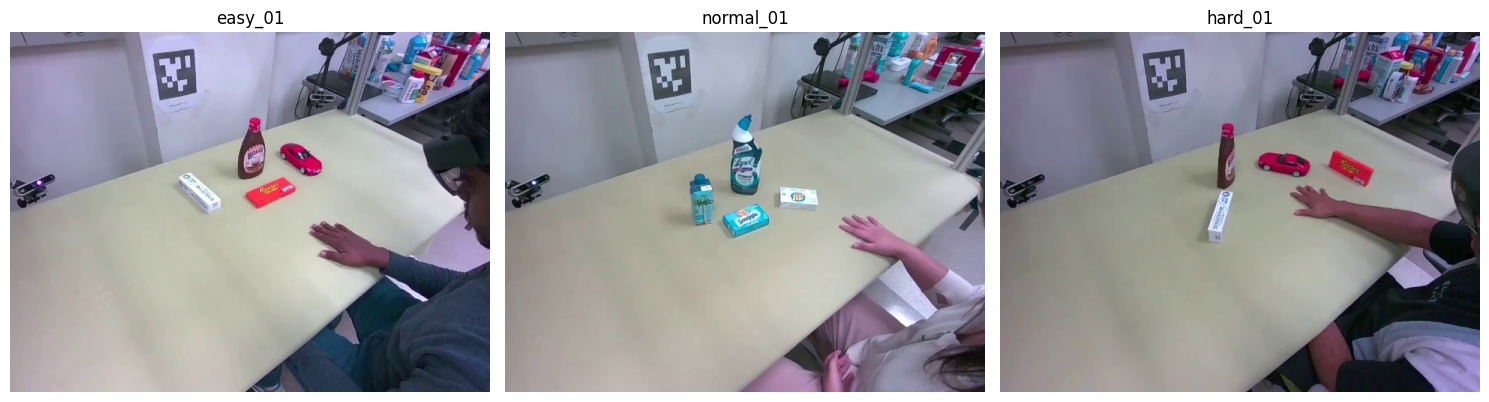

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

sample_ids = ["easy_01", "normal_01", "hard_01"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, video_id in zip(axes, sample_ids):

    frame_path = (
        DATA_DIR / video_id / "frames" / "000000.jpg"
    )

    image = Image.open(frame_path)

    ax.imshow(image)
    ax.set_title(video_id)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from PIL import Image

for video_id in video_ids:

    frames_dir = DATA_DIR / video_id / "frames"

    frames = sorted(frames_dir.glob("*.jpg"))

    first_image = Image.open(frames[0])
    last_image = Image.open(frames[-1])

    print(
        video_id,
        "| Count:", len(frames),
        "| First:", first_image.size,
        "| Last:", last_image.size,
        "| Last filename:", frames[-1].name
    )

easy_01 | Count: 131 | First: (640, 480) | Last: (640, 480) | Last filename: 000130.jpg
easy_02 | Count: 451 | First: (640, 480) | Last: (640, 480) | Last filename: 000450.jpg
normal_01 | Count: 321 | First: (640, 480) | Last: (640, 480) | Last filename: 000320.jpg
normal_02 | Count: 331 | First: (640, 480) | Last: (640, 480) | Last filename: 000330.jpg
hard_01 | Count: 601 | First: (640, 480) | Last: (640, 480) | Last filename: 000600.jpg
hard_02 | Count: 481 | First: (640, 480) | Last: (640, 480) | Last filename: 000480.jpg
